# 결정트리

## 가. 결정 트리(Decision Tree)
### 1. 결정트리의 개념과 원리개념 : 특정 특성의 임계값(Threshold)을 기준으로 데이터를 축에 수직인 경계로 반복 분할하여, 영역 내의 불순도(Impurity)를 최소화하는 대표적인 비선형 알고리즘 
### 2. 스무고개 방식 : IF-THEN 규칙을 적용하여 데이터를 순차적으로 분할
### 3. 장점 :
#### 가) 최고의 설명력 : 판단 근거를 시각적으로 보여주는 화이트박스(White-box) 모델
#### 나) 비선형성 : 복잡한 비선형 관계도 직관적으로 학습
### 4. 단점 :
#### 가) 과대적합(Overfitting) : 데이터의 미세한 노이즈까지 학습하여 트리가 깊어질수록 일반화 성능 저하 


## 나. 불순도(Impurity)와 분할 기준
### 1. 불순도(Impurity) : 서로 다른 데이터가 섞여 있는 정도를 의미하며, 불순도가 낮을수록(순도 100%에 가까울수록) 완벽하게 분류된 상태
### 2. 불순도 지표 :
#### 가) 지니 지수 (Gini Impurity): 기본값(criterion='gini')이며 계산 속도가 빠름
#### 나) 엔트로피 지수 (Entropy) : 정보 이론의 혼잡도 개념을 활용(criterion='entropy')
### 3. CART 알고리즘 (Classification and Regression Trees) :
#### 가) Scikit-Learn이 결정 트리를 훈련할 때 사용하는 대표적인 알고리즘
#### 나) 리프 노드를 제외한 모든 노드가 항상 2개의 자식 노드로 분할되는 이진 트리(Binary Tree)를 생성

In [1]:
# 1. 필요한 라이브러리 및 데이터 불러오기
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn import tree
import pygraphviz as pgv
from IPython.display import Image

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
# Iris 데이터 로드
iris = pd.read_csv("./실습데이터/iris_dataset.csv")
# iris.replace({"setosa" : 0, "versicolor" : 1, "virginica" : 2})
X1 = iris.drop(columns=["label"])
y1 = iris["label"]

In [4]:
# 2. 학습용 및 평가용 데이터 분할
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=0, stratify=y1)

In [5]:
# 3. 결정 트리 분류 모델 생성 (DecisionTreeClassifier)
dt1 = DecisionTreeClassifier()

In [6]:
# 4. 모델 학습
dt1.fit(X1_train, y1_train)
print()

In [7]:
# 5. 평가용 데이터를 이용한 예측
pred_test1 = dt1.predict(X1_test)

In [8]:
# 6. 모델 평가
acc_dt1 = accuracy_score(y1_test, pred_test1)
print(f"Decision Tree Accuracy: {acc_dt1:.4f}")
print("\n[Classification Report]")
print(classification_report(y1_test, pred_test1))

Decision Tree Accuracy: 0.9667

[Classification Report]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [9]:
tree_dot = tree.export_graphviz(
    dt1,
    out_file="./iris_tree.dot.png",
    feature_names=X1.columns, 
    class_names=iris['label'].unique(),
    filled=True
)

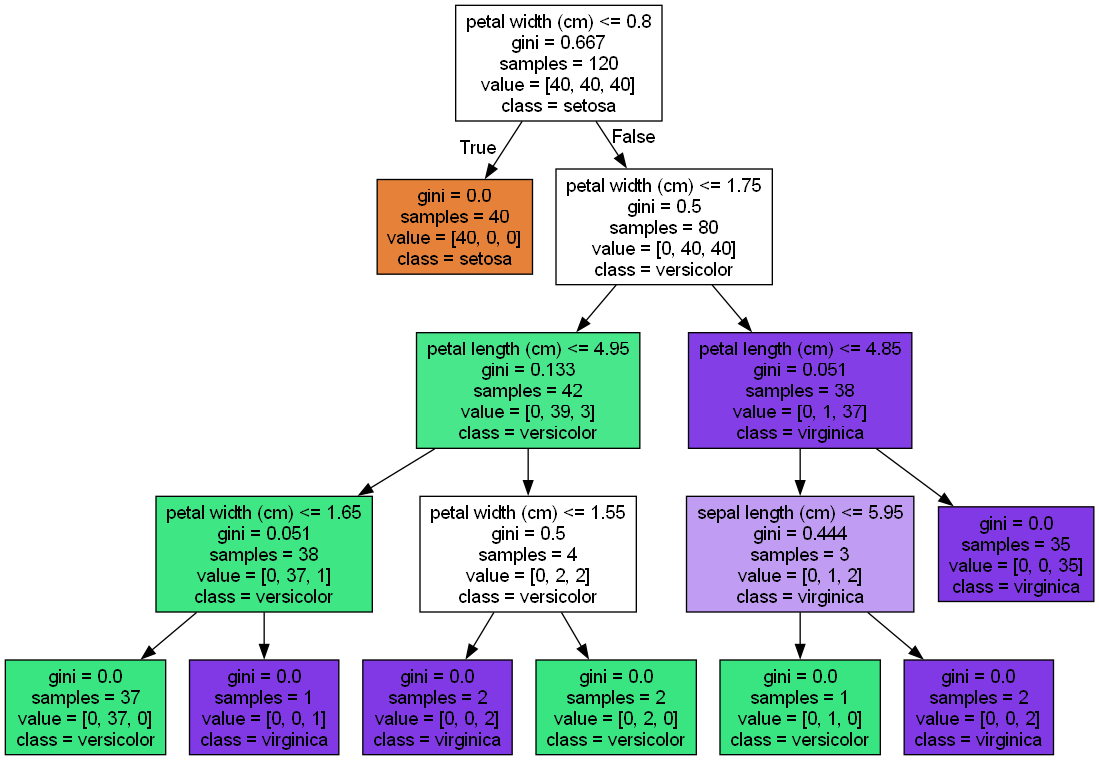

In [10]:
graph = pgv.AGraph("./iris_tree.dot.png")
graph.draw('iris_tree_out.png', prog='dot')
Image('iris_tree_out.png')

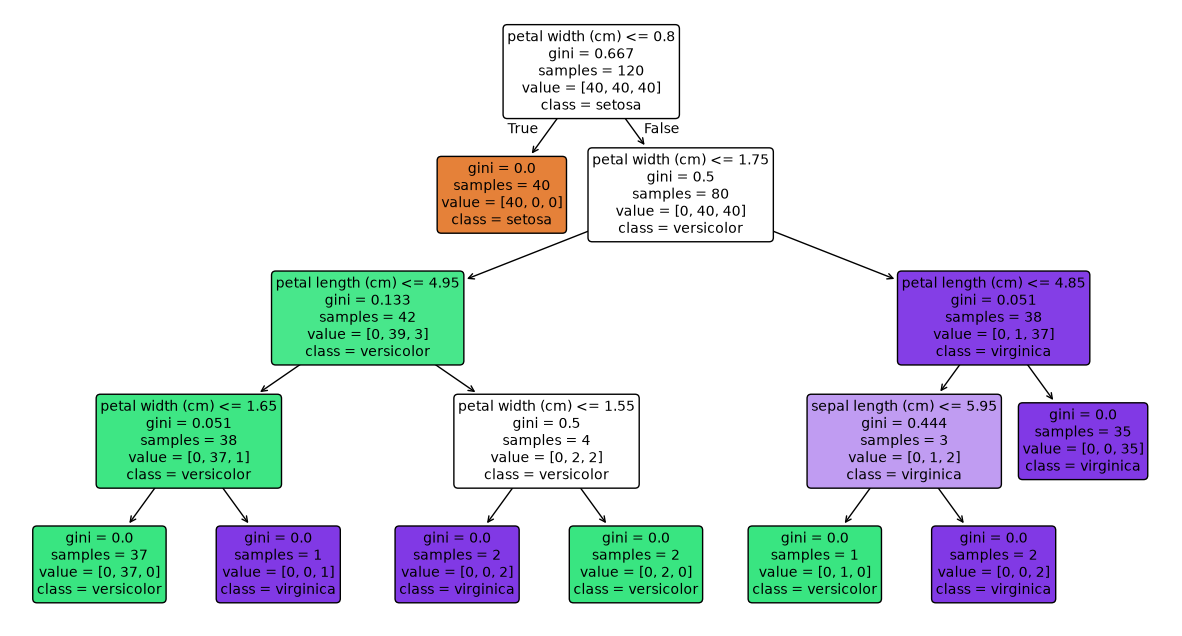

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

# 2. matplotlib을 이용해 의사결정 트리 그리기
tree.plot_tree(
    dt1,
    feature_names=X1.columns,
    class_names=list(
        iris["label"].unique()
    ),  # class_names는 리스트나 문자열 배열 형태여야 합니다.
    filled=True,
    rounded=True,  # 노드 테두리를 둥글게 만들어 줍니다 (선택사항)
    fontsize=10,  # 글씨 크기 조절
)

# 3. 화면에 출력
plt.show()

In [12]:
# 1. 데이터 로드
diabetes = pd.read_csv('./실습데이터/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
X2 = diabetes.drop(columns=['Diabetes_binary'])
y2 = diabetes['Diabetes_binary']

In [13]:
# 2. 학습용 및 평가용 데이터 분할
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=0)


In [14]:
# 3. 결정 트리 분류 모델 생성 (DecisionTreeClassifier)
dt2 = DecisionTreeClassifier(random_state=0)

In [15]:
# 4. 모델 학습
dt2.fit(X2_train, y2_train)
print()


In [16]:
# 5. 평가용 데이터를 이용한 예측
pred_test = dt2.predict(X2_test)

In [17]:
# 6. 모델 평가
accuracy2 = accuracy_score(y2_test, pred_test)
print(f"Accuracy: {accuracy2:.4f}")
print("Confusion Matrix:\n", confusion_matrix(y2_test, pred_test))
print("Classification Report:\n", classification_report(y2_test, pred_test))

Accuracy: 0.6537
Confusion Matrix:
 [[4541 2391]
 [2506 4701]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.64      0.66      0.65      6932
         1.0       0.66      0.65      0.66      7207

    accuracy                           0.65     14139
   macro avg       0.65      0.65      0.65     14139
weighted avg       0.65      0.65      0.65     14139



In [ ]:
plt.figure(figsize=(15, 8))

# 2. matplotlib을 이용해 의사결정 트리 그리기
tree.plot_tree(
    dt2,
    feature_names=X2.columns,
    class_names=[
        "Non-Diabetes (0)",
        "Diabetes (1)",
    ],  # class_names는 리스트나 문자열 배열 형태여야 합니다.
    filled=True,
    rounded=True,  # 노드 테두리를 둥글게 만들어 줍니다 (선택사항)
    fontsize=10,  # 글씨 크기 조절
)

# 3. 화면에 출력
plt.show()